In [1]:
import preprocessamento as pp
import treinamento as tr

import pandas as pd
pd.set_option('display.max_columns', None)
import yfinance as yf


In [2]:
from datetime import datetime, timedelta

In [3]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, precision_score, recall_score
from sklearn.metrics import precision_recall_curve
from sklearn.linear_model import LogisticRegression
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
papel = 'CRFB3.SA'
papeis_adicionais = ['ASAI3.SA', 'PCAR3.SA', 'GMAT3.SA', 'MGLU3.SA', 'LREN3.SA', 'BRFS3.SA']

In [5]:
# Parâmetros
DIAS_VALIDACAO = 90  # número de dias para simular produção

In [6]:
base = datetime.today().date() #- timedelta(days=1)
df_base = pp.montar_dataset(papel, dias_total_historico=600, data_base=base)
#df_base = pp.buscar_dados_papeis_adicionais(df_base, papeis_adicionais)
df_base.tail(10)

[CRFB3.SA] Cache existente cobre de 2020-01-02 a 2025-05-30.
[CRFB3.SA] Cache NÃO cobre período solicitado. Download total necessário.
[CRFB3.SA] Iniciando download de dados (lógica de atualização/complemento)...
[CRFB3.SA] Período de download yfinance: 2020-01-01 a 2025-07-26
Index(['data', 'adj_close', 'close', 'Dividends', 'high', 'low', 'open',
       'Stock Splits', 'volume'],
      dtype='object', name='Price')
[CRFB3.SA] Realizando verificação de divergência entre cache antigo e dados frescos...
[CRFB3.SA] Pós-Download Total: Nenhuma divergência significativa nas amostras (tolerância 1.00%).
[CRFB3.SA] Cache principal ATUALIZADO com dados frescos: /palpiteiro/dados\CRFB3.csv
[CRFB3.SA] Retornando 577 linhas para o período solicitado.
⬇️ Baixando dados macro de 03/02/2022 a 23/07/2025...
Baixando série 432 (selic)...
Baixando série 433 (ipca)...
Baixando série 1 (dolar)...
💾 Dados salvos em cache: /palpiteiro/dados\macro_20220203_20250723.csv
[^BVSP] Cache existente cobre de 2020

,open,high,low,close,adj_close,volume,pct_change,vol,rsi,macd,macd_signal,macd_hist,tr,atr,atr_pct,tr_pct,mm5,mm20,selic,ipca,dolar,open_ibov,high_ibov,low_ibov,close_ibov,adj_close_ibov,volume_ibov
data,,,,,,,,,,,,,,,,,,,,,,,,,,,
2025-05-19,8.41,8.47,8.41,8.45,8.45,1913200,0.002372,0.010912,57.059202,0.116621,0.172201,-0.055580,0.060000,0.125928,0.014903,0.007101,8.458,8.5300,14.75,0.26,5.6591,139186.0,140203.0,138587.0,139636.0,139636.0,4123908
2025-05-20,8.44,8.48,8.43,8.48,8.48,1585300,0.003550,0.008412,58.674345,0.108723,0.159505,-0.050782,0.049999,0.120505,0.014210,0.005896,8.458,8.5330,14.75,0.26,5.6620,139636.0,140244.0,138966.0,140110.0,140110.0,3465298
2025-05-21,8.44,8.49,8.44,8.44,8.44,2325000,-0.004717,0.008446,55.667773,0.098105,0.147225,-0.049120,0.050000,0.115469,0.013681,0.005924,8.456,8.5290,14.75,0.26,5.6571,140109.0,140109.0,137538.0,137881.0,137881.0,3912091
2025-05-22,8.44,8.47,8.43,8.44,8.44,1819300,0.000000,0.004988,55.667773,0.088669,0.135514,-0.046845,0.040000,0.110078,0.013042,0.004739,8.448,8.5220,14.75,0.26,5.6390,137881.0,138837.0,137088.0,137273.0,137273.0,6065741
2025-05-23,8.43,8.48,8.43,8.45,8.45,1641700,0.001185,0.004145,56.316792,0.081062,0.124624,-0.043561,0.049999,0.105787,0.012519,0.005917,8.452,8.5115,14.75,0.26,5.6932,137273.0,137824.0,134997.0,137824.0,137824.0,5062985
2025-05-26,8.48,8.59,8.45,8.47,8.47,1395200,0.002367,0.004144,57.652110,0.075775,0.114854,-0.039079,0.140000,0.108231,0.012778,0.016529,8.456,8.5030,14.75,0.26,5.6619,137824.0,138800.0,137795.0,138136.0,138136.0,3834088
2025-05-27,8.50,8.55,8.45,8.46,8.46,2426600,-0.001181,0.003468,56.718534,0.069971,0.105877,-0.035906,0.100000,0.107643,0.012724,0.011820,8.452,8.4935,14.75,0.26,5.6539,138136.0,140382.0,138136.0,139541.0,139541.0,5172279
2025-05-28,8.49,8.49,8.43,8.43,8.43,2317700,-0.003546,0.003469,53.898815,0.062233,0.097148,-0.034915,0.059999,0.104240,0.012365,0.007117,8.450,8.4845,14.75,0.26,5.6936,139541.0,139547.0,138580.0,138888.0,138888.0,3717190
2025-05-29,8.44,8.49,8.44,8.45,8.45,2956600,0.002372,0.003344,55.487541,0.057057,0.089130,-0.032073,0.059999,0.101080,0.011962,0.007101,8.452,8.4795,14.75,0.26,5.6559,138869.0,139108.0,137993.0,138534.0,138534.0,4519155


## Verificação da volatilidade recente

In [7]:
df_base[['atr', 'atr_pct', 'tr', 'tr_pct']].tail(10)

,atr,atr_pct,tr,tr_pct
data,,,,
2025-05-19,0.125928,0.014903,0.060000,0.007101
2025-05-20,0.120505,0.014210,0.049999,0.005896
2025-05-21,0.115469,0.013681,0.050000,0.005924
2025-05-22,0.110078,0.013042,0.040000,0.004739
2025-05-23,0.105787,0.012519,0.049999,0.005917
2025-05-26,0.108231,0.012778,0.140000,0.016529
2025-05-27,0.107643,0.012724,0.100000,0.011820
2025-05-28,0.104240,0.012365,0.059999,0.007117
2025-05-29,0.101080,0.011962,0.059999,0.007101


In [8]:
ultimo_atr_pct = df_base['atr_pct'].iloc[-1]
multiplo_atr = 1.5
valorizacao_sugerida = ultimo_atr_pct * multiplo_atr
print(f'Último ATR %: {ultimo_atr_pct:.2%}')
print(f'Valorização sugerida: {valorizacao_sugerida:.2%}') 

Último ATR %: 1.19%
Valorização sugerida: 1.79%


## Re-preparação dos dados com valorização sugerida (calibrar dias_futuro de acordo com balanceamento da base)

In [9]:
valorizacao = 0.02
stop_loss = 0.01
DIAS_FUTURO = 1  # dias futuros para buscar a valorização

In [10]:
df = pp.calcular_target_com_stop(df_base, valorizacao_alvo_pct=valorizacao, dias_horizonte_alvo=DIAS_FUTURO, stop_loss_pct=stop_loss)
df['Target'].value_counts(normalize=True)

#0.0    0.789474
#1.0    0.210526

Target
0.0    0.791667
1.0    0.208333
Name: proportion, dtype: float64

In [11]:
# Preparar X e y para treino
DIAS_JANELA_X = 6  # janela de dados recentes que formam cada X
X, y = pp.preparar_X_y_agregado(df, DIAS_JANELA_X, dropna=True, tipo_drop_na='linhas')   

X_train, y_train, X_validacao, y_validacao = tr.dividir_treino_validacao(X, y, DIAS_VALIDACAO, dias_futuro=DIAS_FUTURO)

INFO: 29 linha(s) removidas de X e y devido a NaNs (dropna='linhas').


In [12]:
X_train, removidas = tr.eliminar_features_correlacionadas(X_train, limite_correlacao=0.95, target=y_train)
X_validacao = X_validacao[X_train.columns]
print("Features removidas por alta correlação:", removidas)
print(f"Colunas restantes após filtragem: {X_train.shape[1]}")

Features removidas por alta correlação: ['macd_ultimo', 'dias_queda_pct', 'close_min', 'macd_hist_std', 'macd_hist_ultimo_norm_atr_principal', 'close_std', 'macd_ultimo_norm_atr_principal', 'macd_std', 'ibov_amplitude', 'macd_signal_mean', 'close_max', 'macd_signal_ultimo', 'close_trend', 'close_amplitude', 'close_std_norm_atr_principal', 'macd_mean', 'macd_signal_std', 'rsi_mean']
Colunas restantes após filtragem: 54


In [13]:
X_train.tail()

,close_mean,retorno_desde_mudanca_close,close_dist_min,close_ult_vs_mm_janela,close_vs_mm20,mm5_vs_mm20,retorno_mean,retorno_std,retorno_acumulado,dias_alta_pct,retorno_medio_pos,retorno_medio_neg,volume_mean,volume_std,volume_trend,volume_ult_vs_mean,atr_pct_ultimo,rsi_std,rsi_ultimo,macd_hist_mean,macd_hist_ultimo,tr_mean,tr_std,tr_ultimo,tr_pct_mean,tr_pct_std,tr_pct_ultimo,selic_ultimo,selic_comparacao_anterior,selic_dias_desde_mudanca,ipca_ultimo,ipca_comparacao_anterior,ipca_dias_desde_mudanca,dolar_ultimo,dolar_trend,dolar_std,retorno_desde_mudanca_dolar,ibov_trend,ibov_std,retorno_desde_mudanca_ibov,correl_papel_ibov,beta_papel_ibov,alpha_papel_vs_ibov_mean,atr_ultimo,macd_std_norm_atr_principal,macd_signal_std_norm_atr_principal,macd_signal_ultimo_norm_atr_principal,macd_hist_std_norm_atr_principal,tr_std_norm_atr_principal,tr_ultimo_norm_atr_principal,close_amplitude_norm_atr_principal,dia_semana,feriado,proximo_dia_util
2025-01-10,5.620000,0.000000,0.18,-0.130000,-0.052713,-0.019584,0.001623,0.077092,0.033898,0.5,0.058989,-0.055743,1.858390e+07,5.526919e+06,5.054286e+05,0.061586,0.069073,5.256998,42.928622,0.022984,0.028594,0.403333,0.232694,0.21,0.072079,0.042974,0.038251,12.25,1.0,30,0.16,-1.0,11,6.0965,-0.008797,0.030076,0.000000,-18.457143,929.773879,0.000000,0.931689,7.177450,0.005313,0.379213,0.104470,0.043351,-0.760485,0.072375,0.613625,0.553779,2.215114,4,0,False
2025-01-13,5.610000,-0.043716,0.00,-0.360000,-0.084568,-0.029817,0.000678,0.077708,-0.101027,0.5,0.058989,-0.057633,1.849622e+07,5.580678e+06,-4.674314e+05,-0.165262,0.070745,4.199247,39.914642,0.029149,0.012136,0.400000,0.234777,0.27,0.071548,0.043252,0.051429,12.25,1.0,33,0.16,-1.0,14,6.1079,0.000134,0.020006,0.001870,-338.285714,829.225100,0.000000,0.818476,6.403865,-0.008474,0.371412,0.058383,0.041873,-0.768289,0.044526,0.632119,0.726955,2.423185,0,0,True
2025-01-14,5.525000,0.000000,0.08,-0.195000,-0.058969,-0.046610,-0.013418,0.062265,-0.133333,0.5,0.030798,-0.057633,1.938087e+07,5.393006e+06,-8.000000e+05,0.064065,0.067654,4.178604,41.391761,0.028813,0.008890,0.345000,0.231236,0.22,0.062731,0.043108,0.041276,12.25,1.0,34,0.16,-1.0,15,6.0671,-0.002877,0.023615,0.000000,-345.685714,832.980292,0.002454,0.751881,6.599365,-0.006408,0.360597,0.019667,0.031782,-0.785168,0.047133,0.641259,0.610099,2.495862,1,0,True
2025-01-15,5.426667,0.043152,0.31,0.133333,-0.013047,-0.035768,-0.015073,0.060243,0.029630,0.5,0.027488,-0.057633,2.082695e+07,6.640381e+06,6.828371e+05,0.381244,0.064591,1.974941,45.537194,0.023504,0.023650,0.348333,0.230947,0.34,0.064251,0.042815,0.061151,12.25,1.0,35,0.16,-1.0,16,6.0377,-0.015089,0.032806,-0.004846,395.142857,1406.794323,0.030612,0.623270,1.537939,-0.001508,0.359126,0.022348,0.026193,-0.771921,0.030233,0.643082,0.946744,0.863207,2,0,True
2025-01-16,5.453333,0.000000,0.31,0.106667,-0.010412,-0.032126,0.005252,0.029906,0.005425,0.5,0.027488,-0.025475,1.999547e+07,5.798885e+06,2.481274e+06,0.158373,0.063703,2.239791,45.537194,0.023280,0.034188,0.261667,0.048751,0.29,0.047944,0.008525,0.052158,12.25,1.0,36,0.16,-1.0,17,6.0322,-0.014406,0.031570,-0.005752,541.114286,1501.027304,0.000000,0.625261,1.285011,-0.001736,0.354188,0.041508,0.026196,-0.758551,0.029840,0.137642,0.818774,0.875241,3,0,True


# LogisticRegression

In [14]:
modelo_rl = LogisticRegression(solver='liblinear', penalty='l2', random_state=42, class_weight='balanced', C=0.1)
modelo_rl.fit(X_train, y_train)
tr.comparar_auc_conjuntos(modelo_rl, X_train, y_train, X_validacao, y_validacao)

AUC no treino: 0.530
AUC na validação: 0.507
Diferença AUC (Treino - Validação): 0.023
PR AUC no treino: 0.325
PR AUC na validação: 0.114
Diferença PR AUC (Treino - Validação): 0.211
F1 Score no treino: 0.358
F1 Score na validação: 0.151


(np.float64(0.5302336998233639),
 np.float64(0.5074847221464897),
 np.float64(0.022748977676874227),
 np.float64(0.32526169894008133),
 np.float64(0.11381072271916248),
 np.float64(0.3583106439719502),
 np.float64(0.1505519318912887))

Avaliar e logar modelo
MLflow Tracking URI definido para: file:///C:/palpiteiro/mlruns
Experimento 'Modelo_B3' já existe (ID: 378581376299543397).
  Artifact Location existente: file:///C:/palpiteiro/mlruns/378581376299543397
MLflow Run ID: 36003c8ebdb24aa4a19ec108e0733c75 para CRFB3.SA_6dias_x_0.02val_1dias_alvo
AUC no treino: 0.561
AUC na validação: 0.547

--- Conjunto de Treino --- Janelas

Threshold 0.50 - AUC: 0.530
  Precisão média (em 422 janelas com previsão positiva): 0.278
  Recall médio: 0.605

Calibrando thresholds para precisão mínima de 0.70...
Nenhum threshold atendeu à precisão mínima de 0.70. Seguindo com 0.5

Threshold ideal baseado em mínimo recall ou precisão: 0.50

--- Conjunto de Validação --- Janelas
Precisão média (em 61 janelas com previsão positiva): 0.093
Recall médio: 0.478
Sinais de compra presentes na vallidação: 7.0
Sinais de compra previstos na validação: 38


c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\mlflow\types\utils.py:452: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


Modelo CRFB3.SA_6dias_x_0.02val_1dias_alvo salvo na run 36003c8ebdb24aa4a19ec108e0733c75


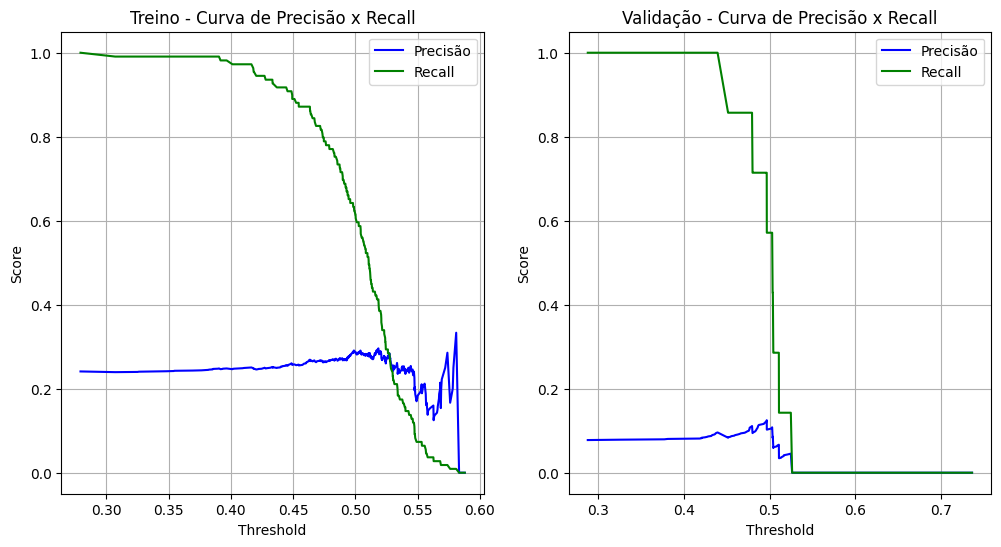

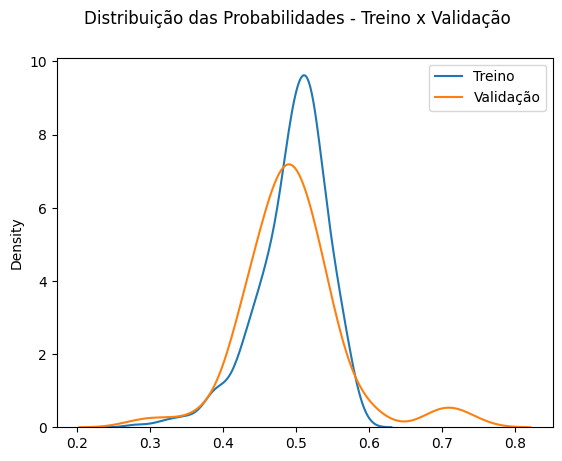

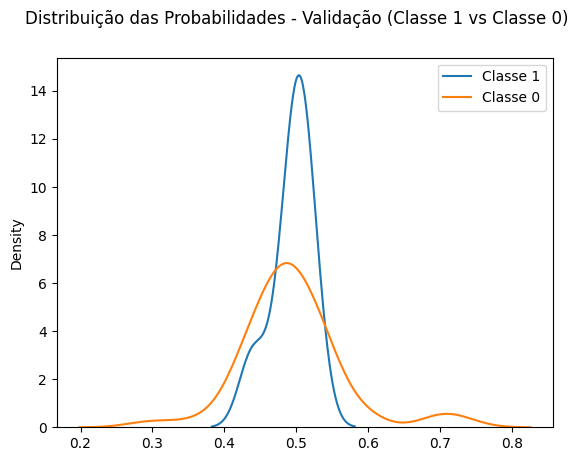

In [15]:
recall_minimo = None
precisao_minima = 0.7
resultado = tr.avaliar_e_logar_modelo(modelo_rl, papel, X_train, y_train, X_validacao, y_validacao, dias_janela_x=DIAS_JANELA_X, valorizacao=valorizacao, stop_loss=stop_loss,dias_futuro_valorizacao=DIAS_FUTURO,dias_validacao=DIAS_VALIDACAO, recall_minimo=recall_minimo, precisao_minima=precisao_minima)
threshold_calibrado = resultado['threshold_calibrado']
probas = resultado['probas_validacao']
y_true = resultado['y_validacao']
y_pred = resultado['y_pred_validacao']

# Redução de features

In [16]:
# Importâncias
importancias = pd.Series(modelo_rl.coef_[0], index=X_train.columns)
df_importancias = pd.DataFrame({
    'Feature': importancias.index,
    'importancia': importancias.values,
    'importancia_abs': importancias.abs().values
})
df_importancias.sort_values(by='importancia_abs', ascending=False, inplace=True)
df_importancias.head(15)


,Feature,importancia,importancia_abs
29,selic_dias_desde_mudanca,0.002179,0.002179
18,rsi_ultimo,0.001692,0.001692
32,ipca_dias_desde_mudanca,-0.001560,0.001560
27,selic_ultimo,0.000280,0.000280
38,ibov_std,-0.000269,0.000269
37,ibov_trend,0.000232,0.000232
0,close_mean,0.000211,0.000211
51,dia_semana,-0.000182,0.000182
28,selic_comparacao_anterior,-0.000124,0.000124
17,rsi_std,0.000104,0.000104



--- Iniciando Avaliação Robusta de k=[5, 10, 15, 20, 25, 30, 35, 40] com Walk-Forward ---
  Resultado Médio para k=5: F1=0.231, Precisão=0.181
  Resultado Médio para k=10: F1=0.251, Precisão=0.212
  Resultado Médio para k=15: F1=0.270, Precisão=0.225
  Resultado Médio para k=20: F1=0.272, Precisão=0.236
  Resultado Médio para k=25: F1=0.267, Precisão=0.231
  Resultado Médio para k=30: F1=0.291, Precisão=0.259
  Resultado Médio para k=35: F1=0.307, Precisão=0.264
  Resultado Médio para k=40: F1=0.295, Precisão=0.247


,k_features,f1_medio,precisao_media,recall_medio,recall_na_precisao_minima,f1_std
0,5,0.230999,0.180907,0.367460,0.042857,0.163393
1,10,0.251091,0.211923,0.430952,0.038095,0.174706
2,15,0.269641,0.224847,0.430952,0.038095,0.158153
3,20,0.271937,0.235554,0.430952,0.069841,0.156592
4,25,0.267307,0.231420,0.430952,0.069841,0.152815
5,30,0.290853,0.259339,0.430952,0.069841,0.126705
6,35,0.307437,0.263959,0.490476,0.125397,0.130737
7,40,0.294738,0.247022,0.490476,0.101587,0.124285


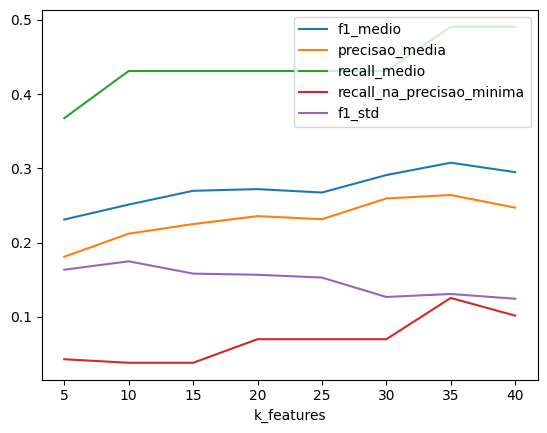

In [17]:
modelo_template_logreg = LogisticRegression(solver='liblinear', random_state=42, class_weight='balanced', penalty='l2', C=0.01) # Exemplo

# 2. Defina os valores de k que você quer testar
k_values_para_teste = list(range(5, 41, 5)) # Ex: [5, 10, 15, 20, 25, 30]

tr.avaliar_k_features_com_walk_forward(
    X_super_treino=X_train,
    y_super_treino=y_train,
    k_values=k_values_para_teste,
    modelo_template=modelo_template_logreg,
    tamanho_janela_treino_wf=180, # Seus parâmetros de janela
    tamanho_janela_validacao_wf=30,
    passo_wf=30,
    precisao_minima_desejada=0.6
)

# Features reduzidas

In [18]:
n_features = 35
lista_colunas_selecionadas = df_importancias.head(n_features)['Feature'].tolist()
lista_colunas_selecionadas

['selic_dias_desde_mudanca',
 'rsi_ultimo',
 'ipca_dias_desde_mudanca',
 'selic_ultimo',
 'ibov_std',
 'ibov_trend',
 'close_mean',
 'dia_semana',
 'selic_comparacao_anterior',
 'rsi_std',
 'proximo_dia_util',
 'dolar_ultimo',
 'macd_signal_ultimo_norm_atr_principal',
 'close_amplitude_norm_atr_principal',
 'correl_papel_ibov',
 'tr_ultimo_norm_atr_principal',
 'dias_alta_pct',
 'close_ult_vs_mm_janela',
 'close_dist_min',
 'ipca_comparacao_anterior',
 'tr_ultimo',
 'macd_signal_std_norm_atr_principal',
 'atr_ultimo',
 'volume_ult_vs_mean',
 'tr_std_norm_atr_principal',
 'beta_papel_ibov',
 'macd_hist_ultimo',
 'macd_std_norm_atr_principal',
 'macd_hist_std_norm_atr_principal',
 'macd_hist_mean',
 'retorno_acumulado',
 'retorno_desde_mudanca_close',
 'tr_std',
 'ipca_ultimo',
 'dolar_trend']

In [19]:
X_train_reduzido = X_train[lista_colunas_selecionadas].copy()
X_validacao_reduzido = X_validacao[lista_colunas_selecionadas].copy()

In [20]:
modelo_rl_reduzido = LogisticRegression(solver='liblinear', random_state=42, class_weight='balanced', C=0.01)
modelo_rl_reduzido.fit(X_train_reduzido, y_train)
tr.comparar_auc_conjuntos(modelo_rl_reduzido, X_train_reduzido, y_train, X_validacao_reduzido, y_validacao)

AUC no treino: 0.561
AUC na validação: 0.629
Diferença AUC (Treino - Validação): -0.068
PR AUC no treino: 0.364
PR AUC na validação: 0.250
Diferença PR AUC (Treino - Validação): 0.114
F1 Score no treino: 0.365
F1 Score na validação: 0.206


(np.float64(0.5613230000153864),
 np.float64(0.6294757808682812),
 np.float64(-0.06815278085289478),
 np.float64(0.36445338280054157),
 np.float64(0.25048301588817873),
 np.float64(0.36474639128092434),
 np.float64(0.20645509152431324))

Avaliar e logar modelo
MLflow Tracking URI definido para: file:///C:/palpiteiro/mlruns
Experimento 'Modelo_B3' já existe (ID: 378581376299543397).
  Artifact Location existente: file:///C:/palpiteiro/mlruns/378581376299543397
MLflow Run ID: 6a0d7d841fb548b0b2fa70c31d1e674e para CRFB3.SA_6dias_x_0.02val_1dias_alvo
AUC no treino: 0.604
AUC na validação: 0.592

--- Conjunto de Treino --- Janelas

Threshold 0.50 - AUC: 0.561
  Precisão média (em 423 janelas com previsão positiva): 0.278
  Recall médio: 0.587

Calibrando thresholds para precisão mínima de 0.70...
Nenhum threshold atendeu à precisão mínima de 0.70. Seguindo com 0.5

Threshold ideal baseado em mínimo recall ou precisão: 0.50

--- Conjunto de Validação --- Janelas
Precisão média (em 61 janelas com previsão positiva): 0.130
Recall médio: 0.719
Sinais de compra presentes na vallidação: 7.0
Sinais de compra previstos na validação: 54


c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\mlflow\types\utils.py:452: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


Modelo CRFB3.SA_6dias_x_0.02val_1dias_alvo salvo na run 6a0d7d841fb548b0b2fa70c31d1e674e


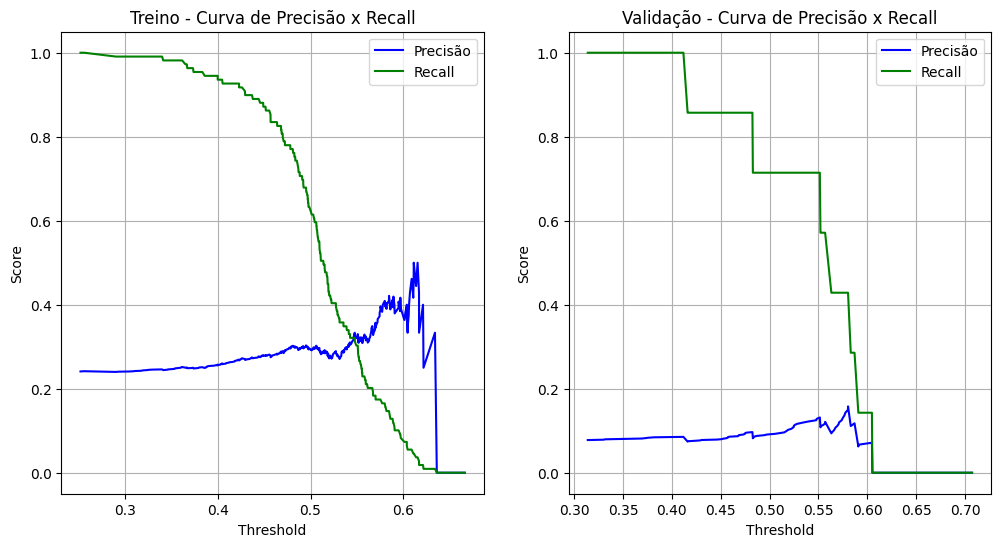

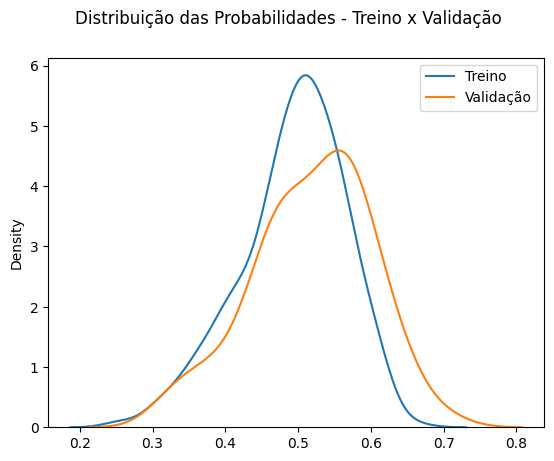

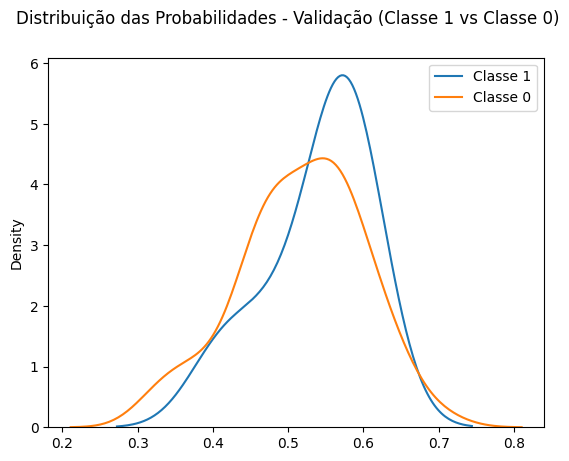

In [21]:
recall_minimo = None
precisao_minima = 0.7
resultado = tr.avaliar_e_logar_modelo(modelo_rl_reduzido, papel, X_train_reduzido, y_train, X_validacao_reduzido, y_validacao, dias_janela_x=DIAS_JANELA_X, valorizacao=valorizacao, stop_loss=stop_loss, dias_futuro_valorizacao=DIAS_FUTURO,dias_validacao=DIAS_VALIDACAO, recall_minimo=recall_minimo, precisao_minima=precisao_minima)
threshold_calibrado = resultado['threshold_calibrado']
probas = resultado['probas_validacao']
y_true = resultado['y_validacao']
y_pred = resultado['y_pred_validacao']

# LGBM GOOGLE

## Versão com early stopping

In [22]:
from lightgbm import LGBMClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import TimeSeriesSplit # Para o CV interno da calibração, se optar por essa via
from sklearn.metrics import roc_auc_score
import lightgbm as lgbm # Para o callback de early stopping
from sklearn.frozen import FrozenEstimator

def criar_e_treinar_modelo_final_com_es_e_calib(
        X_super_treino_completo: pd.DataFrame, # Seus 510 dias
        y_super_treino_completo: pd.Series,
        fracao_eval_es: float = 0.2, # % do X_super_treino a ser usado para eval_set do Early Stopping
        lgbm_params: dict = None,
        early_stopping_rounds_lgbm: int = 50,
        eval_metric_lgbm: str = 'auc',
        calibrar_modelo: bool = True,
        metodo_calibracao: str = 'isotonic',
        # Opção A para calibração: usar o mesmo eval_set_es para cv='prefit'
        # Opção B para calibração: usar TimeSeriesSplit no X_treino_base_lgbm para cv do CalibratedCV
        estrategia_calibracao_cv = 'prefit' # ou um objeto TimeSeriesSplit(n_splits=3)
        , class_weight: str = 'balanced' 
    ):
    """
    Treina o modelo final (LGBM) usando uma parte do X_super_treino_completo para treino
    e outra parte para early stopping. Opcionalmente calibra o modelo.

    Retorna o modelo final treinado (e possivelmente calibrado).
    """
    if not (0 < fracao_eval_es < 1):
        raise ValueError("fracao_eval_es deve estar entre 0 e 1 (exclusivo).")

    n_total_super_treino = len(X_super_treino_completo)
    n_eval_es = int(n_total_super_treino * fracao_eval_es)
    n_treino_base_lgbm = n_total_super_treino - n_eval_es

    if n_treino_base_lgbm < 50 or n_eval_es < 20: # Mínimos arbitrários, ajuste conforme necessário
        raise ValueError(f"Dados insuficientes no X_super_treino para o split de early stopping. "
                         f"Treino Base: {n_treino_base_lgbm}, Eval ES: {n_eval_es}")

    X_treino_base_lgbm = X_super_treino_completo.iloc[:n_treino_base_lgbm]
    y_treino_base_lgbm = y_super_treino_completo.iloc[:n_treino_base_lgbm]
    X_eval_set_es = X_super_treino_completo.iloc[n_treino_base_lgbm:]
    y_eval_set_es = y_super_treino_completo.iloc[n_treino_base_lgbm:]

    print(f"Dividindo Super Treino ({n_total_super_treino} amostras):")
    print(f"  - Treino Base LGBM: {len(X_treino_base_lgbm)} amostras")
    print(f"  - Eval Set p/ Early Stopping (e possivelmente Calibração 'prefit'): {len(X_eval_set_es)} amostras")

    # --- 1. Treinar LGBM com Early Stopping ---
    if lgbm_params is None:
        lgbm_params = {
            'n_estimators': 1000, 'learning_rate': 0.01, 'num_leaves': 8,
            'max_depth': 3, 'min_child_samples': 20, 'subsample': 0.8,
            'colsample_bytree': 0.8, 'random_state': 42, 'n_jobs': -1,
            'class_weight': class_weight,
            'importance_type': 'gain', 
            'verbose': -1 # Desativa logs do LGBM

        }

    modelo_lgbm = LGBMClassifier(**lgbm_params)
    print(f"\nIniciando treinamento LGBM com early stopping (monitorando '{eval_metric_lgbm}')...")

    # Certificar que X_treino_base_lgbm.values e X_eval_set_es.values são usados se as funções esperam arrays
    # Se X são DataFrames, LGBM geralmente lida bem, mas para consistência com sklearn:
    X_treino_lgbm_arr = X_treino_base_lgbm.values if isinstance(X_treino_base_lgbm, pd.DataFrame) else X_treino_base_lgbm
    y_treino_lgbm_arr = y_treino_base_lgbm.values if isinstance(y_treino_base_lgbm, pd.Series) else y_treino_base_lgbm
    X_eval_es_arr = X_eval_set_es.values if isinstance(X_eval_set_es, pd.DataFrame) else X_eval_set_es
    y_eval_es_arr = y_eval_set_es.values if isinstance(y_eval_set_es, pd.Series) else y_eval_set_es

    modelo_lgbm.fit(
        X_treino_lgbm_arr, y_treino_lgbm_arr,
        eval_set=[(X_eval_es_arr, y_eval_es_arr)],
        eval_metric=eval_metric_lgbm,
        callbacks=[lgbm.early_stopping(stopping_rounds=early_stopping_rounds_lgbm, verbose=10)]
    )
    print(f"Treinamento LGBM concluído. Melhor iteração: {modelo_lgbm.best_iteration_}")
    # Após o ES, o modelo_lgbm já está treinado com o número ótimo de árvores.

    if not calibrar_modelo:
        return modelo_lgbm # Retorna o LGBM treinado sem calibração

    # --- 2. Calibrar o Modelo Treinado ---
    print(f"\nCalibrando o LGBM treinado (método: {metodo_calibracao})...")
    
    

    if estrategia_calibracao_cv == "prefit":
        # Usa o X_eval_set_es para treinar o calibrador.
        # Este conjunto já foi "visto" para determinar n_estimators, então não é 100% puro
        # para calibração, mas é uma prática comum.
        print(f"  Usando conjunto de early stopping ({len(X_eval_set_es)} amostras) para treinar o calibrador (cv='prefit').")

        modelo_frozen = FrozenEstimator(modelo_lgbm) # Congela o modelo LGBM treinado com ES
        modelo_final_calibrado = CalibratedClassifierCV(
            modelo_frozen, # O modelo LGBM JÁ TREINADO com ES e congelado
            method=metodo_calibracao            
            )
        modelo_final_calibrado.fit(X_eval_es_arr, y_eval_es_arr)
    elif isinstance(estrategia_calibracao_cv, TimeSeriesSplit):
        modelo_final_calibrado = CalibratedClassifierCV(
            modelo_lgbm, # O modelo LGBM JÁ TREINADO com ES
            method=metodo_calibracao,
            cv=estrategia_calibracao_cv # Pode ser "prefit" ou um objeto TimeSeriesSplit
            )
        # Treina o CalibratedClassifierCV no X_treino_base_lgbm.
        # O CalibratedCV irá internamente usar o LGBM (já com n_estimators ótimo)
        # e fazer cross-validation no X_treino_base_lgbm para ajustar o calibrador.
        # O estimador base (LGBM) NÃO é retreinado do zero pelo CalibratedCV se já tiver fit e cv='prefit'
        # MAS, se cv é um objeto splitter, ele *pode* retreinar o base_estimator em cada fold.
        # Para evitar retreinar o LGBM que já teve ES, a abordagem com 'prefit' é mais direta.
        # Se você quiser usar um splitter para o CV da calibração, é mais seguro
        # passar um LGBM *não treinado* para CalibratedCV, e o CalibratedCV fará o fit
        # do LGBM e do calibrador em seus folds internos. Mas aí você perde o ES global.
        
        # A maneira mais limpa se não usar 'prefit' para o CalibratedCV é
        # fazer com que ele treine um LGBM novo (sem ES global) em seus folds.
        # Ou, você pode fazer o ES em cada fold do CalibratedCV (mais complexo).

        # Simplificação: Se não for 'prefit', vamos assumir que você quer que o CalibratedCV
        # treine o LGBM base (com os params definidos) e o calibrador nos folds do X_treino_base_lgbm.
        # Isso ignora o `modelo_lgbm` treinado com ES anteriormente, a menos que
        # o `base_estimator` do CalibratedCV seja clonado e o `n_estimators` ótimo seja setado.
        # Vamos manter a lógica de 'prefit' como principal ou usar CV no conjunto de treino base.
        print(f"  Usando TimeSeriesSplit no Treino Base LGBM ({len(X_treino_base_lgbm)} amostras) para treinar o calibrador.")
        
        # Reinstanciar o LGBM com os parâmetros e n_estimators ótimos
        # para ser usado pelo CalibratedClassifierCV com seu próprio CV.
        # Isso garante que o n_estimators do ES seja usado em cada fold do CalibratedCV.
        params_lgbm_com_best_iter = modelo_lgbm.get_params()
        if hasattr(modelo_lgbm, 'best_iteration_') and modelo_lgbm.best_iteration_ is not None:
             params_lgbm_com_best_iter['n_estimators'] = modelo_lgbm.best_iteration_
        
        lgbm_para_calib_cv = LGBMClassifier(**params_lgbm_com_best_iter)

        modelo_final_calibrado_cv = CalibratedClassifierCV(
            lgbm_para_calib_cv,
            method=metodo_calibracao,
            cv=estrategia_calibracao_cv
        )
        modelo_final_calibrado_cv.fit(X_treino_lgbm_arr, y_treino_lgbm_arr) # Treina no treino base
        print("Calibração com CV interno concluída.")
        return modelo_final_calibrado_cv # Retorna o modelo calibrado com CV
    else:
        raise ValueError(f"estrategia_calibracao_cv desconhecida: {estrategia_calibracao_cv}. Use 'prefit' ou um objeto TimeSeriesSplit.")

    print("Calibração concluída.")
    return modelo_final_calibrado, modelo_lgbm

In [26]:
# --- Seu fluxo principal (para cada papel) ---
# Supondo que X_super_train_papel, y_super_train_papel (510 dias)
# e X_validacao_final_papel, y_validacao_final_papel (90 dias) estão definidos.

# 1. Treinar o modelo
#    Você escolhe a estratégia de calibração:
#    Opção A: Calibrar com 'prefit' usando o mesmo eval_set do ES (mais simples, pequeno reuso)
modelo_treinado, modelo_original = criar_e_treinar_modelo_final_com_es_e_calib(
    X_train, y_train,
    fracao_eval_es=0.2, # Ex: 20% do super treino para ES e calibração prefit
    estrategia_calibracao_cv='prefit'
    , class_weight='balanced' # Ajuste conforme necessário
)
#modelo_treinado.fit(X_train.values, y_train.values)  # Fit final após calibração

#    Opção B: Calibrar com TimeSeriesSplit no conjunto de treino base do LGBM
#    (LGBM com n_estimators do ES é retreinado dentro dos folds do CalibratedCV)
#    tscv_para_calibracao = TimeSeriesSplit(n_splits=3)
#    modelo_treinado = criar_e_treinar_modelo_final_com_es_e_calib(
#        X_super_train_papel, y_super_train_papel,
#        fracao_eval_es=0.2, # Define o tamanho do eval_set_es, o resto é treino_base_lgbm
#        estrategia_calibracao_cv=tscv_para_calibracao
#    )
tr.comparar_auc_conjuntos(modelo_treinado, X_train, y_train, X_validacao, y_validacao)

Dividindo Super Treino (452 amostras):
  - Treino Base LGBM: 362 amostras
  - Eval Set p/ Early Stopping (e possivelmente Calibração 'prefit'): 90 amostras

Iniciando treinamento LGBM com early stopping (monitorando 'auc')...
Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[1]	valid_0's auc: 0.43191	valid_0's binary_logloss: 0.694119
Treinamento LGBM concluído. Melhor iteração: 1

Calibrando o LGBM treinado (método: isotonic)...
  Usando conjunto de early stopping (90 amostras) para treinar o calibrador (cv='prefit').
Calibração concluída.


c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with f

AUC no treino: 0.628
AUC na validação: 0.516
Diferença AUC (Treino - Validação): 0.112
PROVÁVEL OVERFITTING
PR AUC no treino: 0.315
PR AUC na validação: 0.083
Diferença PR AUC (Treino - Validação): 0.232
F1 Score no treino: 0.000
F1 Score na validação: 0.000


(np.float64(0.6277010947836731),
 np.float64(0.515575789388678),
 np.float64(0.1121253053949951),
 np.float64(0.3152048626087776),
 np.float64(0.08334608499636642),
 np.float64(0.0),
 np.float64(0.0))

In [27]:
recall_minimo = None
precisao_minima = 0.65
resultado = tr.avaliar_e_logar_modelo(modelo_treinado, papel, X_train, y_train, X_validacao, y_validacao, dias_janela_x=DIAS_JANELA_X, valorizacao=valorizacao, stop_loss=stop_loss,dias_futuro_valorizacao=DIAS_FUTURO,dias_validacao=DIAS_VALIDACAO, recall_minimo=recall_minimo, precisao_minima=precisao_minima)
threshold_calibrado = resultado['threshold_calibrado']
probas = resultado['probas_validacao']
y_true = resultado['y_validacao']
y_pred = resultado['y_pred_validacao']

Avaliar e logar modelo
MLflow Tracking URI definido para: file:///C:/palpiteiro/mlruns
Experimento 'Modelo_B3' já existe (ID: 378581376299543397).
  Artifact Location existente: file:///C:/palpiteiro/mlruns/378581376299543397
MLflow Run ID: e6904879451e44a3a7d0580b98f27c6e para CRFB3.SA_6dias_x_0.02val_1dias_alvo
AUC no treino: 0.641
AUC na validação: 0.560

--- Conjunto de Treino --- Janelas

Threshold 0.50 - AUC: 0.628
  Precisão média (em 0 janelas com previsão positiva): 0.000
  Recall médio: 0.000


KeyboardInterrupt: 

(<Axes: >,
 count    90.000000
 mean      0.210782
 std       0.176741
 min       0.000000
 25%       0.000000
 50%       0.194444
 75%       0.357143
 max       0.500000
 dtype: float64)

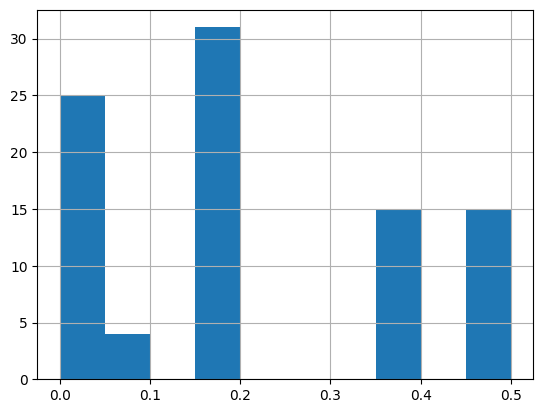

In [ ]:
pd.Series(probas).hist(), pd.Series(probas).describe()

# Redução de features

In [ ]:
# Importâncias
importancias = pd.Series(modelo_original.feature_importances_, index=X_train.columns)
importancias = importancias.sort_values(ascending=False)
importancias.head(15)


close_vs_adc_close_mean_geral            593.602402
adc_correl_com_principal_BEEF3           301.161100
dolar_trend                              168.918600
close_amplitude_norm_atr_principal        90.541520
adc_correl_com_principal_BRFS3            84.953588
macd_signal_mean                          59.739935
macd_signal_ultimo_norm_atr_principal     52.640001
adc_atr_pct_ultimo_BEEF3                  48.530800
tr_std                                    32.812199
ibov_trend                                23.509001
macd_ultimo_norm_atr_principal            22.926100
adc_rsi_ultimo_JBSS3                      22.244801
close_trend                               17.977699
adc_correl_com_principal_JBSS3            16.024582
correl_papel_ibov                         11.575900
dtype: float64

In [ ]:
import matplotlib.pyplot as plt
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score

def avaliar_precisao_recall_por_k_janelas(X_train, y_train, X_valid, y_valid, k_values, importancias, janela_treino=180, janela_teste=30):
    resultados_precisao = {}
    resultados_recall = {}

    for k in k_values:        
        colunas_selecionadas = importancias.head(k).index.tolist()        
        precisões = []
        recalls = []

        for i in range(0, len(X_valid) - janela_teste):
            X_val_teste = X_valid.iloc[i:i + janela_teste][colunas_selecionadas]
            y_val_teste = y_valid.iloc[i:i + janela_teste]

            #modelo = RandomForestClassifier(n_estimators=100, random_state=42)
            
            modelo, _ = criar_e_treinar_modelo_final_com_es_e_calib(
                X_train[colunas_selecionadas], y_train,
                fracao_eval_es=0.2, # Ex: 20% do super treino para ES e calibração prefit
                estrategia_calibracao_cv='prefit'
            )            

            y_pred = modelo.predict(X_val_teste)

            if (y_pred == 1).sum() > 0:
                # Se não houver predições positivas, não calcular precisão e recall
                
                prec = precision_score(y_val_teste, y_pred, zero_division=0)
                rec = recall_score(y_val_teste, y_pred, zero_division=0)

                precisões.append(prec)
                recalls.append(rec)

        resultados_precisao[k] = np.mean(precisões)
        resultados_recall[k] = np.mean(recalls)

    return resultados_precisao, resultados_recall

# Altere se quiser outro intervalo de k
k_values = list(range(5, min(51, X_train.shape[1] + 1), 5))
#k_values = [18, 20, 22, 25]
resultados_precisao, resultados_recall = avaliar_precisao_recall_por_k_janelas(X_train, y_train, X_validacao, y_validacao, k_values, importancias)

In [ ]:
resultados_precisao

{5: np.float64(nan),
 10: np.float64(nan),
 15: np.float64(nan),
 20: np.float64(nan),
 25: np.float64(0.0),
 30: np.float64(0.2811688311688311),
 35: np.float64(nan),
 40: np.float64(nan),
 45: np.float64(0.5968266852195424),
 50: np.float64(nan)}

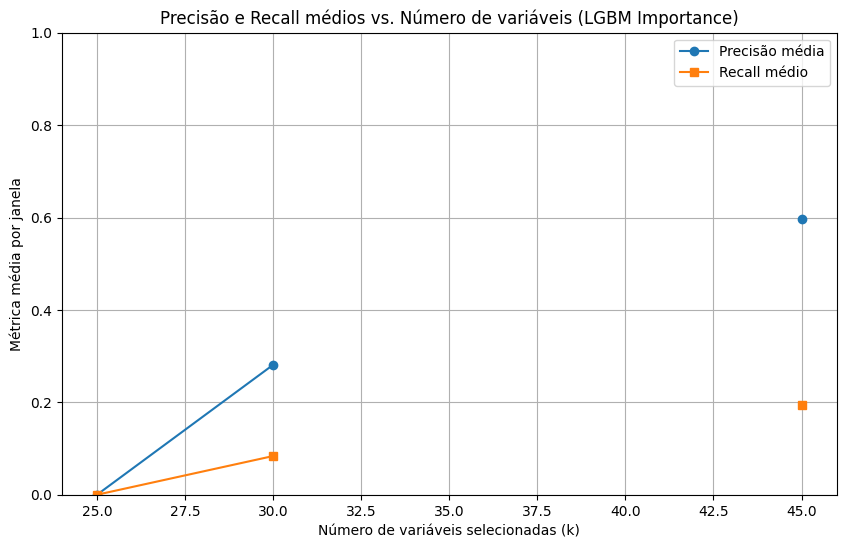

In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(resultados_precisao.keys(), resultados_precisao.values(), marker='o', label='Precisão média')
plt.plot(resultados_recall.keys(), resultados_recall.values(), marker='s', label='Recall médio')
plt.title("Precisão e Recall médios vs. Número de variáveis (LGBM Importance)")
plt.xlabel("Número de variáveis selecionadas (k)")
plt.ylabel("Métrica média por janela")
plt.ylim(0, 1)
plt.legend()
plt.grid(True)
plt.show()

# Features reduzidas

In [ ]:
n_features = 55
lista_colunas_selecionadas = importancias.head(n_features).index.tolist()
lista_colunas_selecionadas

['close_vs_adc_close_mean_geral',
 'adc_correl_com_principal_BEEF3',
 'dolar_trend',
 'close_amplitude_norm_atr_principal',
 'adc_correl_com_principal_BRFS3',
 'macd_signal_mean',
 'macd_signal_ultimo_norm_atr_principal',
 'adc_atr_pct_ultimo_BEEF3',
 'tr_std',
 'ibov_trend',
 'macd_ultimo_norm_atr_principal',
 'adc_rsi_ultimo_JBSS3',
 'close_trend',
 'adc_correl_com_principal_JBSS3',
 'correl_papel_ibov',
 'retorno_desde_mudanca_close',
 'beta_papel_ibov',
 'macd_std',
 'macd_hist_std_norm_atr_principal',
 'ibov_std',
 'retorno_desde_mudanca_ibov',
 'volume_mean',
 'adc_rsi_ultimo_BEEF3',
 'retorno_desde_mudanca_dolar',
 'adc_macd_hist_ultimo_BRFS3',
 'rsi_std',
 'retorno_medio_pos',
 'close_amplitude',
 'close_min',
 'dias_queda_pct',
 'dias_alta_pct',
 'retorno_acumulado',
 'retorno_std',
 'retorno_mean',
 'mm5_vs_mm20',
 'close_vs_mm20',
 'close_ult_vs_mm_janela',
 'close_dist_min',
 'volume_ult_vs_mean',
 'rsi_ultimo',
 'macd_signal_std',
 'atr_pct_ultimo',
 'volume_trend',
 'volu

In [ ]:
X_train_reduzido = X_train[lista_colunas_selecionadas].copy()
X_validacao_reduzido = X_validacao[lista_colunas_selecionadas].copy()

In [ ]:
modelo_reduzido, _ = criar_e_treinar_modelo_final_com_es_e_calib(
    X_train_reduzido, y_train,
    fracao_eval_es=0.2, # Ex: 20% do super treino para ES e calibração prefit
    estrategia_calibracao_cv='prefit'    
)

#    Opção B: Calibrar com TimeSeriesSplit no conjunto de treino base do LGBM
#    (LGBM com n_estimators do ES é retreinado dentro dos folds do CalibratedCV)
#    tscv_para_calibracao = TimeSeriesSplit(n_splits=3)
#    modelo_treinado = criar_e_treinar_modelo_final_com_es_e_calib(
#        X_super_train_papel, y_super_train_papel,
#        fracao_eval_es=0.2, # Define o tamanho do eval_set_es, o resto é treino_base_lgbm
#        estrategia_calibracao_cv=tscv_para_calibracao
#    )
tr.comparar_auc_conjuntos(modelo_reduzido, X_train_reduzido, y_train, X_validacao_reduzido, y_validacao)

Dividindo Super Treino (485 amostras):
  - Treino Base LGBM: 388 amostras
  - Eval Set p/ Early Stopping (e possivelmente Calibração 'prefit'): 97 amostras

Iniciando treinamento LGBM com early stopping (monitorando 'auc')...
Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[15]	valid_0's auc: 0.662662	valid_0's binary_logloss: 0.631605
Treinamento LGBM concluído. Melhor iteração: 15

Calibrando o LGBM treinado (método: isotonic)...
  Usando conjunto de early stopping (97 amostras) para treinar o calibrador (cv='prefit').
Calibração concluída.


c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with f

AUC no treino: 0.814
AUC na validação: 0.541
Diferença AUC (Treino - Validação): 0.274
PROVÁVEL OVERFITTING
PR AUC no treino: 0.505
PR AUC na validação: 0.428
Diferença PR AUC (Treino - Validação): 0.076
F1 Score no treino: 0.492
F1 Score na validação: 0.166


(np.float64(0.8141250496064021),
 np.float64(0.5406060128178298),
 np.float64(0.27351903678857226),
 np.float64(0.5045786748870741),
 np.float64(0.42818864226659953),
 np.float64(0.4923051803128624),
 np.float64(0.16609950196239195))

Avaliar e logar modelo
MLflow Run ID: b6c57f7fee6d4037bfafea7b5b8f712b para MRFG3.SA_6dias_x_0.07val_5dias_alvo
AUC no treino: 0.790
AUC na validação: 0.562

--- Conjunto de Treino --- Janelas

Threshold 0.50 - AUC: 0.814
  Precisão média (em 442 janelas com previsão positiva): 0.379
  Recall médio: 0.848

Calibrando thresholds para precisão mínima de 0.60...
Nenhum threshold atendeu à precisão mínima de 0.60. Seguindo com 0.5

Threshold ideal baseado em mínimo recall ou precisão: 0.50

--- Conjunto de Validação --- Janelas
Precisão média (em 52 janelas com previsão positiva): 0.437
Recall médio: 0.119
Sinais de compra presentes na vallidação: 27.0
Sinais de compra previstos na validação: 13
Modelo MRFG3.SA_6dias_x_0.07val_5dias_alvo salvo na run b6c57f7fee6d4037bfafea7b5b8f712b


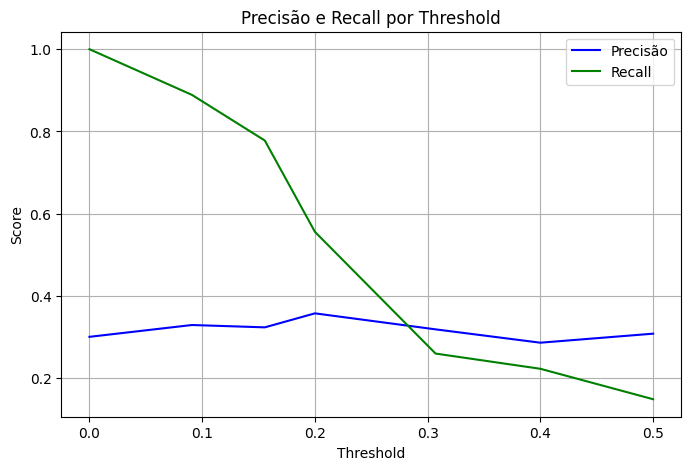

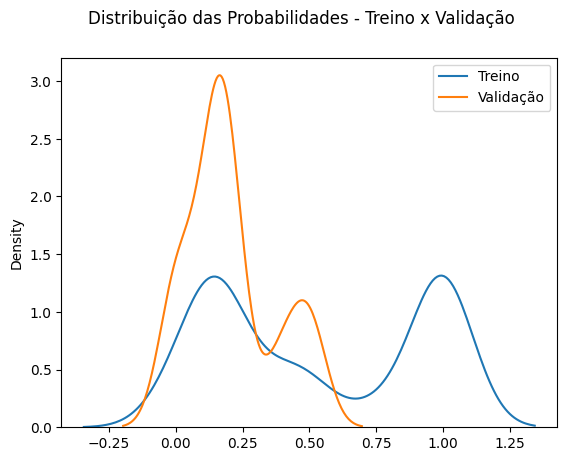

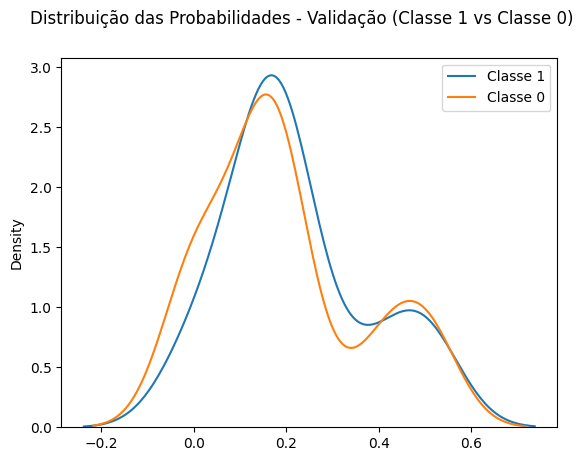

In [ ]:
precisao_minima = 0.6
recall_minimo = None
resultado = tr.avaliar_e_logar_modelo(modelo_reduzido, papel, X_train_reduzido, y_train, X_validacao_reduzido, y_validacao, dias_janela_x=DIAS_JANELA_X, valorizacao=valorizacao, dias_futuro_valorizacao=DIAS_FUTURO, dias_validacao=DIAS_VALIDACAO, recall_minimo=recall_minimo, precisao_minima=precisao_minima)
threshold_calibrado = resultado['threshold_calibrado']
probas = resultado['probas_validacao']
y_true = resultado['y_validacao']
y_pred = resultado['y_pred_validacao']

<Axes: >

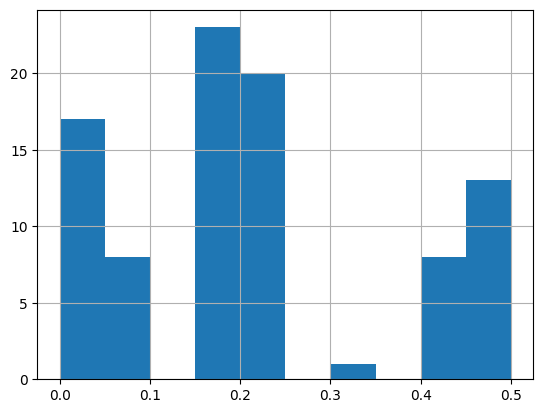

In [ ]:
pd.Series(probas).hist()

In [ ]:
pd.Series(probas).describe()

count    90.000000
mean      0.203468
std       0.161489
min       0.000000
25%       0.090909
50%       0.155556
75%       0.200000
max       0.500000
dtype: float64